# Choose K at a fixed cutoff: repeated-sample validation

Use $\Omega=450$, independent samples of size $n=100$ from $N(0,1)$, and $N=50$ bandwidths geometrically spaced from $h_{\min}=0.01$ to $h_{\max}=2$.

For each realization and each candidate $K$, compare **all Gram entries, including the diagonal**, with the analytic Gaussian formula:

$$E_m(K)=\max_{r,s}|\widetilde G_{rs}^{(m),K,\Omega}-G_{rs}^{(m)}|.$$

The reference is [the thesis's Equation `eq:beta2_exact_formula02`](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex), implemented in [density.py](../kde_tools/density.py). Approximations call the existing [direct frequency-quadrature helper](../kde_tools/fourier/similarities.py), with **K intervals and K+1 nodes**.

The first 150 realizations form a calibration set and the final 50 form an independent verification set. The selection rule uses the calibration set only: choose the smallest tested K whose largest Gram error is at most half the requested tolerance. The verification result is reported separately and does not change this choice. This is empirical validation, rather than a guarantee for all samples.

The total error measured here includes both truncation and quadrature. The uniform truncation bound derived in this chat is $\operatorname{erfc}(h_{\min}\Omega)/(2\sqrt{\pi}h_{\min})$; the Gaussian-tail identity is [DLMF 7.2.2](https://dlmf.nist.gov/7.2.E2). A tight reference agreement can reflect cancellation, so the separate maximum divergence error is also recorded.

Every displayed figure is automatically exported to `../outputs/pdfs/g_rs_k_validation/`. Settings, the actual samples and bandwidths, numerical results, and PNG previews are saved under `../outputs/` in a configuration-specific directory. Timing covers Gram construction only.


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import os
import platform
import sys

code_directory = next(
    (candidate.resolve()
     for ancestor in (Path.cwd(), *Path.cwd().parents)
     for candidate in (ancestor, ancestor / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from inside the MASTERARBEIT project.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
from scipy.special import erfc

from kde_tools.density import exact_gaussian_kde_l2_gram
from kde_tools.fourier import FOURIER_L2_METHOD_VERSION, gaussian_kde_l2_gram_fourier
from kde_tools.pdf_export import enable_automatic_pdf_saving

notebook_name = "g_rs_k_validation"
pdf_output_directory = enable_automatic_pdf_saving(notebook_name)


In [2]:
# Requested sample and bandwidth settings.
frequency_cutoff = 450.0
n = 100
N = 50
h_min = 0.01
h_max = 2.0

# Experiment settings: calibration and independent verification.
realizations = 200
calibration_realizations = 150
seed = 20261025
K_candidates = np.array([128, 256, 512, 768, 1024, 1280, 1408, 1536, 1719, 2048, 4096])
absolute_tolerance = 1e-8
selection_margin_fraction = 0.5

bandwidths = np.geomspace(h_min, h_max, N)
settings = {
    "method_version": FOURIER_L2_METHOD_VERSION,
    "reference": "analytic_gaussian_kde_l2_gram_float64",
    "sample_distribution": "standard_normal",
    "bandwidth_grid": "geometric",
    "frequency_cutoff": frequency_cutoff,
    "n": n, "N": N, "h_min": h_min, "h_max": h_max,
    "realizations": realizations,
    "calibration_realizations": calibration_realizations,
    "seed": seed, "seed_rule": "seed + realization_index",
    "K_candidates": K_candidates.tolist(),
    "absolute_tolerance": absolute_tolerance,
    "selection_margin_fraction": selection_margin_fraction,
}
configuration_id = hashlib.sha256(
    json.dumps(settings, sort_keys=True).encode()
).hexdigest()[:12]
data_directory = code_directory / "outputs" / "data" / notebook_name / configuration_id
image_directory = code_directory / "outputs" / "images" / notebook_name / configuration_id
data_directory.mkdir(parents=True, exist_ok=True)
image_directory.mkdir(parents=True, exist_ok=True)
print(f"Configuration: {configuration_id}")


Configuration: a932fe7ce8ca


In [3]:
if not 0 < calibration_realizations < realizations:
    raise ValueError("Require separate, nonempty calibration and verification sets.")
if (K_candidates.ndim != 1 or len(K_candidates) == 0
        or not np.issubdtype(K_candidates.dtype, np.integer)
        or np.any(K_candidates < 1) or np.any(np.diff(K_candidates) <= 0)):
    raise ValueError("K_candidates must be increasing, unique positive integers.")
if not 0 < selection_margin_fraction <= 1:
    raise ValueError("Require 0 < selection_margin_fraction <= 1.")

# Generate and preserve every sample; reuse it for all candidate K values.
samples = np.stack([
    np.random.default_rng(seed + repetition).normal(size=n)
    for repetition in range(realizations)
])
np.save(data_directory / "samples.npy", samples)
np.save(data_directory / "bandwidths.npy", bandwidths)
(data_directory / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")

shape = (realizations, len(K_candidates))
maximum_gram_errors = np.empty(shape)
maximum_divergence_errors = np.empty(shape)
fourier_seconds = np.empty(shape)
exact_seconds = np.empty(realizations)
worst_r = np.empty(shape, dtype=int)
worst_s = np.empty(shape, dtype=int)

# Warm up the existing approximation helper before collecting timings.
gaussian_kde_l2_gram_fourier(
    samples[0], bandwidths, frequency_cutoff=frequency_cutoff,
    frequency_points=int(K_candidates[-1]) + 1,
)
experiment_start = perf_counter()
for repetition, current_sample in enumerate(samples):
    start = perf_counter()
    exact_gram = exact_gaussian_kde_l2_gram(current_sample, bandwidths)
    exact_seconds[repetition] = perf_counter() - start
    exact_diagonal = np.diag(exact_gram)
    exact_divergence = np.maximum(
        0.5 * exact_diagonal[:, None] + 0.5 * exact_diagonal[None, :] - exact_gram,
        0.0,
    )
    # Randomize candidate order independently of the sample to reduce order bias.
    candidate_order = np.random.default_rng(seed + 1000000 + repetition).permutation(len(K_candidates))
    for candidate_index in candidate_order:
        current_K = int(K_candidates[candidate_index])
        start = perf_counter()
        approximate_gram = gaussian_kde_l2_gram_fourier(
            current_sample, bandwidths,
            frequency_cutoff=frequency_cutoff,
            frequency_points=current_K + 1,
        )
        fourier_seconds[repetition, candidate_index] = perf_counter() - start
        errors = np.abs(approximate_gram - exact_gram)
        r, s = np.unravel_index(np.argmax(errors), errors.shape)
        maximum_gram_errors[repetition, candidate_index] = errors[r, s]
        worst_r[repetition, candidate_index] = r
        worst_s[repetition, candidate_index] = s
        approximate_diagonal = np.diag(approximate_gram)
        approximate_divergence = np.maximum(
            0.5 * approximate_diagonal[:, None] + 0.5 * approximate_diagonal[None, :] - approximate_gram,
            0.0,
        )
        maximum_divergence_errors[repetition, candidate_index] = np.max(
            np.abs(approximate_divergence - exact_divergence)
        )
    if (repetition + 1) % 25 == 0:
        print(f"Completed {repetition + 1}/{realizations} realizations "
              f"({perf_counter() - experiment_start:.1f} s).", flush=True)

calibration_errors = maximum_gram_errors[:calibration_realizations]
verification_errors = maximum_gram_errors[calibration_realizations:]
selection_threshold = selection_margin_fraction * absolute_tolerance
eligible = np.flatnonzero(np.max(calibration_errors, axis=0) <= selection_threshold)
selected_index = int(eligible[0]) if len(eligible) else None
selected_K = int(K_candidates[selected_index]) if selected_index is not None else None
uniform_truncation_bound = float(erfc(h_min * frequency_cutoff) / (2 * np.sqrt(np.pi) * h_min))

summary_rows = []
for j, current_K in enumerate(K_candidates):
    summary_rows.append([
        current_K, frequency_cutoff / current_K,
        np.median(maximum_gram_errors[:, j]),
        np.quantile(maximum_gram_errors[:, j], 0.95),
        np.max(maximum_gram_errors[:, j]),
        np.max(calibration_errors[:, j]),
        np.max(verification_errors[:, j]),
        np.count_nonzero(calibration_errors[:, j] > absolute_tolerance),
        np.count_nonzero(verification_errors[:, j] > absolute_tolerance),
        np.median(fourier_seconds[:, j]),
        np.max(maximum_divergence_errors[:, j]),
    ])
summary_table = np.asarray(summary_rows)
np.savetxt(
    data_directory / "summary.csv", summary_table, delimiter=",", comments="",
    header="K,delta_omega,median_max_gram_error,p95_max_gram_error,worst_max_gram_error,calibration_worst,verification_worst,calibration_failures,verification_failures,median_fourier_seconds,worst_divergence_error",
)
np.savez_compressed(
    data_directory / "per_realization_results.npz",
    K_candidates=K_candidates, maximum_gram_errors=maximum_gram_errors,
    maximum_divergence_errors=maximum_divergence_errors,
    fourier_seconds=fourier_seconds, exact_seconds=exact_seconds,
    worst_r=worst_r, worst_s=worst_s,
)
report = {
    **settings, "configuration_id": configuration_id,
    "platform": platform.platform(), "numpy_version": np.__version__,
    "thread_environment": {key: os.environ.get(key) for key in (
        "VECLIB_MAXIMUM_THREADS", "OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS")},
    "tested_pairs_per_realization": N * N,
    "uniform_truncation_bound": uniform_truncation_bound,
    "selection_threshold": selection_threshold,
    "selected_K_from_calibration": selected_K,
    "verification_worst_at_selected_K": (
        float(np.max(verification_errors[:, selected_index])) if selected_index is not None else None),
    "verification_passes_tolerance": (
        bool(np.all(verification_errors[:, selected_index] <= absolute_tolerance)) if selected_index is not None else None),
    "verification_passes_selection_margin": (
        bool(np.all(verification_errors[:, selected_index] <= selection_threshold)) if selected_index is not None else None),
    "all_realizations_worst_at_selected_K": (
        float(np.max(maximum_gram_errors[:, selected_index])) if selected_index is not None else None),
    "median_exact_seconds": float(np.median(exact_seconds)),
    "median_fourier_seconds_at_selected_K": (
        float(np.median(fourier_seconds[:, selected_index])) if selected_index is not None else None),
    "experiment_seconds": perf_counter() - experiment_start,
}
(data_directory / "report.json").write_text(json.dumps(report, indent=2) + "\n")
print(f"Calibration-selected K: {selected_K}")
print(f"Independent verification worst error: {report['verification_worst_at_selected_K']}")
print(f"Uniform tail bound: {uniform_truncation_bound:.6g}")
print("K, worst Gram error, verification failures, median Fourier milliseconds")
for row in summary_table:
    print(f"{int(row[0]):4d}  {row[4]:.6e}  {int(row[8]):3d}  {1000*row[9]:.3f}")


Completed 25/200 realizations (3.6 s).
Completed 50/200 realizations (7.0 s).
Completed 75/200 realizations (10.3 s).
Completed 100/200 realizations (13.7 s).
Completed 125/200 realizations (17.1 s).
Completed 150/200 realizations (20.5 s).
Completed 175/200 realizations (23.9 s).
Completed 200/200 realizations (27.4 s).
Calibration-selected K: 1408
Independent verification worst error: 4.7157718008339344e-09
Uniform tail bound: 5.54644e-09
K, worst Gram error, verification failures, median Fourier milliseconds
 128  4.371377e-01   50  0.555
 256  1.573731e-01   50  0.999
 512  2.187798e-02   50  1.931
 768  1.044363e-03   50  2.870
1024  1.698488e-05   50  3.832
1280  9.830848e-08   49  4.707
1408  4.715772e-09    0  5.141
1536  1.617429e-10    0  5.606
1719  1.204508e-10    0  6.243
2048  1.204647e-10    0  7.375
4096  1.204891e-10    0  14.211


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/g_rs_k_validation/001_accuracy_at_fixed_omega_450_n_100_n_50_h_in_0_01_2_200_realizations.pdf


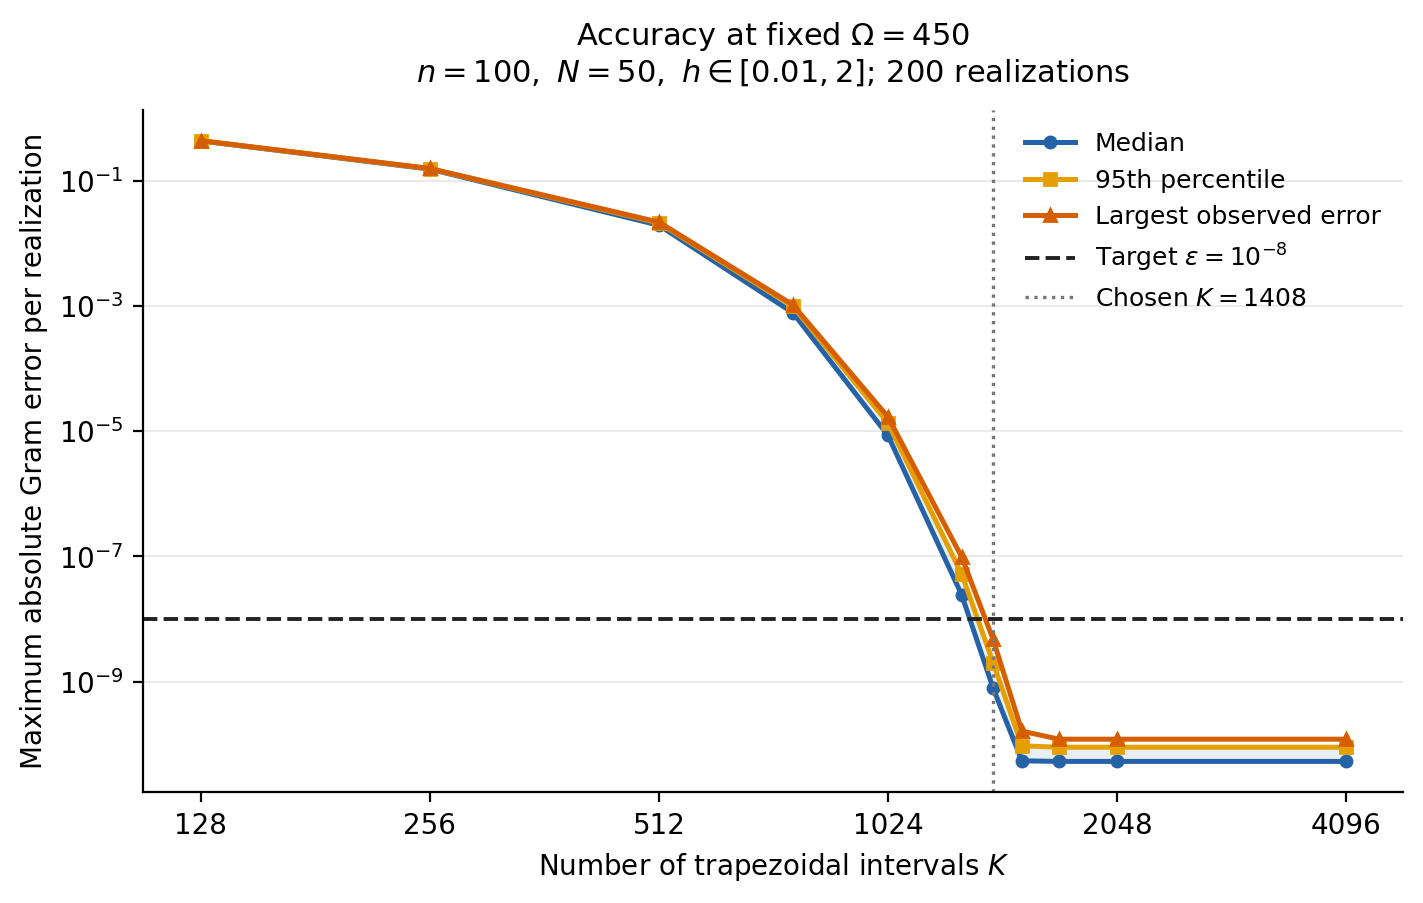

In [4]:
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
}):
    fig_accuracy, ax_accuracy = plt.subplots(figsize=(7.0, 4.4), layout="constrained")
    ax_accuracy.fill_between(
        K_candidates, summary_table[:, 2], summary_table[:, 3],
        color="#2563a6", alpha=0.10,
    )
    ax_accuracy.plot(K_candidates, summary_table[:, 2], "o-", color="#2563a6",
                     markersize=4, linewidth=1.8, label="Median")
    ax_accuracy.plot(K_candidates, summary_table[:, 3], "s-", color="#e69f00",
                     markersize=4, linewidth=1.8, label="95th percentile")
    ax_accuracy.plot(K_candidates, summary_table[:, 4], "^-", color="#d55e00",
                     markersize=4, linewidth=1.8, label="Largest observed error")
    ax_accuracy.axhline(absolute_tolerance, color="#222222", linestyle="--", linewidth=1.4,
                        label=rf"Target $\varepsilon=10^{{{np.log10(absolute_tolerance):g}}}$")
    if selected_K is not None:
        ax_accuracy.axvline(selected_K, color="#777777", linestyle=":", linewidth=1.2,
                            label=rf"Chosen $K={selected_K}$")
    ax_accuracy.set_xscale("log", base=2)
    ax_accuracy.set_yscale("log")
    ax_accuracy.set_xticks([128, 256, 512, 1024, 2048, 4096])
    ax_accuracy.xaxis.set_major_formatter(ScalarFormatter())
    ax_accuracy.set_xlabel(r"Number of trapezoidal intervals $K$")
    ax_accuracy.set_ylabel(r"Maximum absolute Gram error per realization")
    ax_accuracy.set_title(
        r"Accuracy at fixed $\Omega=450$" + "\n"
        + rf"$n={n},\ N={N},\ h\in[{h_min:g},{h_max:g}]$; {realizations} realizations",
        fontsize=11, pad=10,
    )
    ax_accuracy.grid(axis="y", color="#e6e6e6", linewidth=0.6)
    ax_accuracy.set_axisbelow(True)
    ax_accuracy.legend(loc="upper right", frameon=False, fontsize=9)
    accuracy_png_path = image_directory / "g_rs_k_validation_accuracy.png"
    fig_accuracy.savefig(accuracy_png_path, dpi=200, bbox_inches="tight")
    plt.show()


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/g_rs_k_validation/002_gram_calculation_time_at_fixed_omega_450_n_100_n_50_medians_over_200_realization.pdf


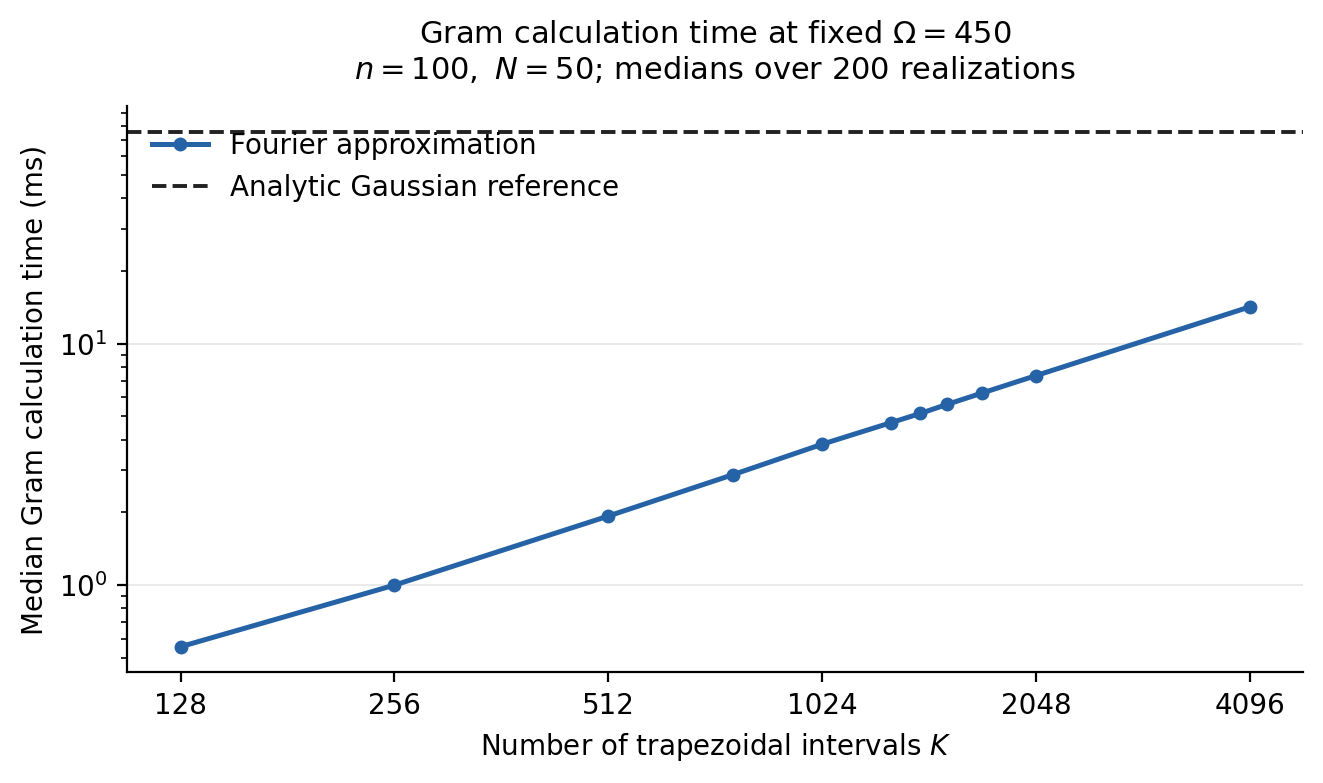

In [5]:
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
}):
    fig_timing, ax_timing = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
    ax_timing.plot(K_candidates, 1000 * summary_table[:, 9], "o-", color="#2563a6",
                   markersize=4, linewidth=1.8, label="Fourier approximation")
    ax_timing.axhline(1000 * np.median(exact_seconds), color="#222222", linestyle="--",
                      linewidth=1.4, label="Analytic Gaussian reference")
    ax_timing.set_xscale("log", base=2)
    ax_timing.set_yscale("log")
    ax_timing.set_xticks([128, 256, 512, 1024, 2048, 4096])
    ax_timing.xaxis.set_major_formatter(ScalarFormatter())
    ax_timing.set_xlabel(r"Number of trapezoidal intervals $K$")
    ax_timing.set_ylabel("Median Gram calculation time (ms)")
    ax_timing.set_title(
        r"Gram calculation time at fixed $\Omega=450$" + "\n"
        + rf"$n={n},\ N={N}$; medians over {realizations} realizations",
        fontsize=11, pad=10,
    )
    ax_timing.grid(axis="y", color="#e6e6e6", linewidth=0.6)
    ax_timing.set_axisbelow(True)
    ax_timing.legend(loc="upper left", frameon=False)
    timing_png_path = image_directory / "g_rs_k_validation_timing.png"
    fig_timing.savefig(timing_png_path, dpi=200, bbox_inches="tight")
    plt.show()
